In [77]:
import pandas as pd 
import numpy as np
import datetime         #Shows in my time zone COL.

BBB-880 AIR2
8B51422F

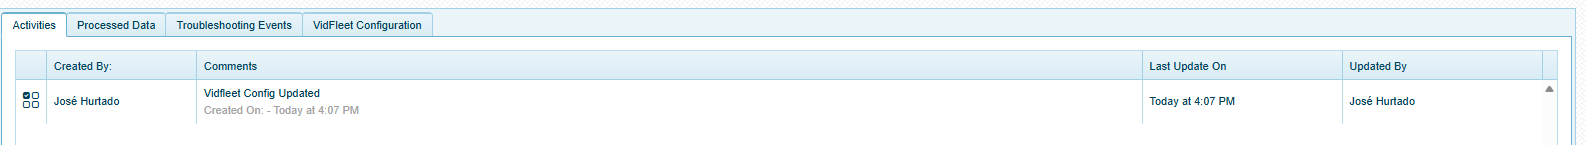
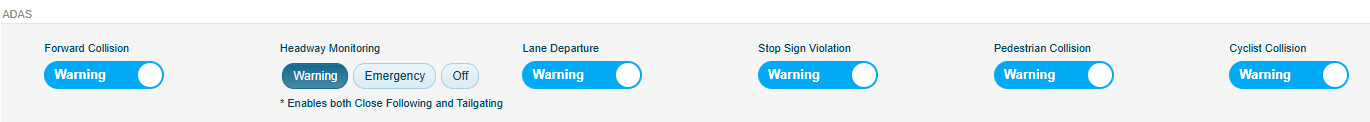

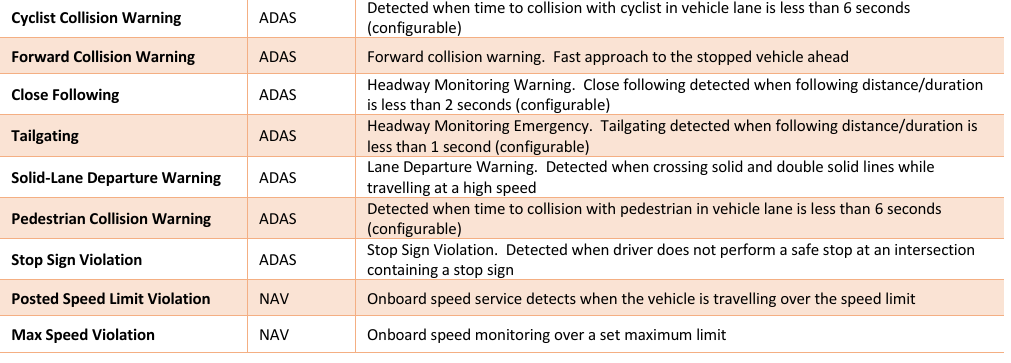

In [78]:
vf=pd.read_excel(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F.xlsx')
vf.info()

<class 'pandas.DataFrame'>
RangeIndex: 15063 entries, 0 to 15062
Columns: 404 entries, Message to Unnamed: 403
dtypes: float64(27), object(19), str(358)
memory usage: 46.4+ MB


In [79]:
vf['Message'].value_counts()

Message
{"notificationType":"TripInfo"              11288
{"notificationType":"CameraRunningInfo"      1609
{"notificationType":"AutoSnapshot"           1285
{"notificationType":"IgnitionStatus"          600
{"notificationType":"CameraEvent"             131
{"notificationType":"PowerEvent"               77
{"notificationType":"MaintenanceWarning"       40
{"notificationType":"ParkingHeartbeat"         33
Name: count, dtype: int64

In [80]:
vf_camera_events=vf[vf['Message'].str.contains('CameraEvent')]
vf_camera_events['Unnamed: 4'].value_counts()

Unnamed: 4
event:"USING_PHONE"                     41
event:"LANE_DEPARTURE_WARNING"          35
event:"HEADWAY_MONITORING_EMERGENCY"    12
event:"NO_SEATBELT"                     12
event:"YAWN"                            10
event:"POTENTIAL_INCIDENT_LOW"           9
event:"HARD_BRAKE"                       3
event:"SHARP_TURN"                       3
event:"DROWSINESS"                       2
event:"POTENTIAL_INCIDENT_MEDIUM"        1
event:"FORWARD_COLLISION_WARNING"        1
event:"HARSH_BRAKE"                      1
event:"HARD_ACCEL"                       1
Name: count, dtype: int64

In [81]:
vf_camera_events['Unnamed: 5'].value_counts()

Unnamed: 5
eventCategory:"DMS"                   65
eventCategory:"LANE_DEPARTURE"        35
eventCategory:"HEADWAY_MONITORING"    12
eventCategory:"POTENTIAL_INCIDENT"    10
eventCategory:"HARD_BRAKE"             4
eventCategory:"SHARP_TURN"             3
eventCategory:"FORWARD_COLLISION"      1
eventCategory:"HARD_ACCEL"             1
Name: count, dtype: int64

In [82]:
vf_autosnapshot=vf[vf['Unnamed: 5'].str.contains('http')]
vf_autosnapshot['Unnamed: 5']#.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sedisa\snapshot.csv')

3        url:"https://cdn.vidfleet-api.gpstrackit.com/c...
19       url:"https://cdn.vidfleet-api.gpstrackit.com/c...
42       url:"https://cdn.vidfleet-api.gpstrackit.com/c...
45       url:"https://cdn.vidfleet-api.gpstrackit.com/c...
68       url:"https://cdn.vidfleet-api.gpstrackit.com/c...
                               ...                        
15021    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
15025    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
15034    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
15056    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
15062    url:"https://cdn.vidfleet-api.gpstrackit.com/c...
Name: Unnamed: 5, Length: 1285, dtype: str

In [83]:
vf_date_time=vf[vf['Unnamed: 3'].str.contains('time')]
vf_date_time['Unnamed: 3']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
print(vf_date_time.iloc[0,103])

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,3][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i])

nan
2026-09-30 19:01:50.066000  ->  1790812910.066
2026-09-30 19:21:49.666000  ->  1790814109.666
2026-09-30 19:38:59.733000  ->  1790815139.733
2026-09-30 19:45:55  ->  1790815555.0
2026-09-30 20:05:54.666000  ->  1790816754.666
2026-09-30 20:08:58.666000  ->  1790816938.666
2026-09-30 20:12:08  ->  1790817128.0
2026-09-30 20:45:58  ->  1790819158.0
2026-09-30 20:55:58  ->  1790819758.0
2026-09-30 21:15:58.066000  ->  1790820958.066
2026-09-30 21:21:53.800000  ->  1790821313.8
2026-10-01 05:43:41  ->  1790851421.0
2026-10-01 05:53:41  ->  1790852021.0
2026-10-01 06:03:39.133000  ->  1790852619.133
2026-10-01 06:23:38.933000  ->  1790853818.933
2026-10-01 06:43:39.066000  ->  1790855019.066
2026-10-01 06:53:39.066000  ->  1790855619.066
2026-10-01 07:13:37.266000  ->  1790856817.266
2026-10-01 07:23:37.333000  ->  1790857417.333
2026-10-01 07:33:39.333000  ->  1790858019.333
2026-10-01 07:43:37.200000  ->  1790858617.2
2026-10-01 07:51:48.200000  ->  1790859108.2
2026-10-01 08:40:15  -

In [84]:
vf_autosnapshot=vf[vf['Unnamed: 5'].str.contains('http')]
vf_autosnapshot_date=[]
aux_date_time_as=[]
epoch_date_as=[]
vf_autosnapshot['Date']='NaN'

for i in range(0,vf_autosnapshot.shape[0]):
    aux_date_time_as.append(float(vf_date_time.iloc[i,3][5:18])/1000)
    epoch_date_as.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_autosnapshot.iloc[i,104]=str(epoch_date_as[i])

#vf_autosnapshot[['Unnamed: 5','Unnamed: 3','Date']].to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\sedisa\autosnap_vck379.csv')       #Edit.

NO_SEATBELT


In [85]:
vf_no_seatbelt=vf[vf['Unnamed: 4'].str.contains('NO_SEATBELT')]
#vf_no_seatbelt

vf_date_time=vf_no_seatbelt[vf_no_seatbelt['Unnamed: 9'].str.contains('time')]
#vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))    
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-03 19:22:44  ->  1791073364.0  ->  speed:46.988945
2026-10-12 23:45:45  ->  1791866745.0  ->  speed:54.58029
2026-10-13 15:15:08  ->  1791922508.0  ->  speed:54.32101
2026-10-15 05:50:19  ->  1792061419.0  ->  speed:78.63777
2026-10-15 18:44:20  ->  1792107860.0  ->  speed:58.76396
2026-10-15 21:20:41  ->  1792117241.0  ->  speed:48.552032
2026-10-17 10:59:39  ->  1792252779.0  ->  speed:63.91993
2026-10-19 19:31:56  ->  1792456316.0  ->  speed:66.87572
2026-10-19 19:36:48  ->  1792456608.0  ->  speed:71.368675
2026-10-24 16:48:08  ->  1792878488.0  ->  speed:61.006733
2026-10-24 16:51:56  ->  1792878716.0  ->  speed:51.980083
2026-10-24 16:54:06  ->  1792878846.0  ->  speed:42.236713


USING_PHONE

In [86]:
using_phone=vf[vf['Unnamed: 4'].str.contains('USING_PHONE')]
#vf_no_seatbelt

vf_date_time=using_phone[using_phone['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-01 15:28:39  ->  1790886519.0  ->  speed:51.444855
2026-10-03 19:27:34  ->  1791073654.0  ->  speed:61.360462
2026-10-06 05:46:06  ->  1791283566.0  ->  speed:47.737152
2026-10-07 06:22:38  ->  1791372158.0  ->  speed:45.544384
2026-10-07 06:27:03  ->  1791372423.0  ->  speed:56.598972
2026-10-07 16:54:13  ->  1791410053.0  ->  speed:46.875973
2026-10-09 15:09:45  ->  1791576585.0  ->  speed:44.36466
2026-10-09 15:13:48  ->  1791576828.0  ->  speed:42.803425
2026-10-10 19:24:33  ->  1791678273.0  ->  speed:52.71718
2026-10-12 08:25:23  ->  1791811523.0  ->  speed:63.769917
2026-10-13 14:47:30  ->  1791920850.0  ->  speed:65.58488
2026-10-13 22:36:02  ->  1791948962.0  ->  speed:55.66186
2026-10-14 00:29:15  ->  1791955755.0  ->  speed:78.972984
2026-10-14 07:11:14  ->  1791979874.0  ->  speed:41.803345
2026-10-14 10:11:52  ->  1791990712.0  ->  speed:45.870335
2026-10-14 11:05:51  ->  1791993951.0  ->  speed:45.22584
2026-10-14 11:51:24  ->  1791996684.0  ->  speed:63.0606
2026

DROWSINESS

In [87]:
drowsiness=vf[vf['Unnamed: 4'].str.contains('DROWSINESS')]
#vf_no_seatbelt

vf_date_time=drowsiness[drowsiness['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-11 10:15:19  ->  1791731719.0  ->  speed:16.706892
2026-10-18 15:32:50  ->  1792355570.0  ->  speed:13.471447


YAWN

In [88]:
yawn=vf[vf['Unnamed: 4'].str.contains('YAWN')]
#vf_no_seatbelt

vf_date_time=yawn[yawn['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-09 06:48:42  ->  1791546522.0  ->  speed:68.6129
2026-10-13 17:32:25  ->  1791930745.0  ->  speed:64.07179
2026-10-15 06:54:45  ->  1792065285.0  ->  speed:65.59969
2026-10-15 20:59:08  ->  1792115948.0  ->  speed:88.49597
2026-10-19 12:15:14  ->  1792430114.0  ->  speed:69.049965
2026-10-22 17:38:08  ->  1792708688.0  ->  speed:77.05617
2026-10-27 05:56:27  ->  1793098587.0  ->  speed:54.658077
2026-10-27 06:04:41  ->  1793099081.0  ->  speed:79.8212
2026-10-27 06:10:38  ->  1793099438.0  ->  speed:56.97678
2026-10-27 19:56:35  ->  1793148995.0  ->  speed:60.027023


SHARP_TURN

In [89]:
sharp_turn=vf[vf['Unnamed: 4'].str.contains('SHARP')]
#vf_no_seatbelt

vf_date_time=sharp_turn[sharp_turn['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-14 06:48:37  ->  1791978517.0  ->  speed:35.20837
2026-10-22 07:08:06  ->  1792670886.0  ->  speed:43.016403
2026-10-22 06:56:08  ->  1792670168.0  ->  speed:39.92912


HARD_BRAKE

In [90]:
hard_brake=vf[vf['Unnamed: 4'].str.contains('HARD')]
#vf_no_seatbelt

vf_date_time=hard_brake[hard_brake['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

2026-10-09 19:38:47  ->  1791592727.0  ->  speed:27.439232
2026-10-12 05:09:08  ->  1791799748.0  ->  speed:9.732259
2026-10-20 14:48:34  ->  1792525714.0  ->  speed:6.798692
2026-10-24 09:56:28  ->  1792853788.0  ->  speed:80.33606


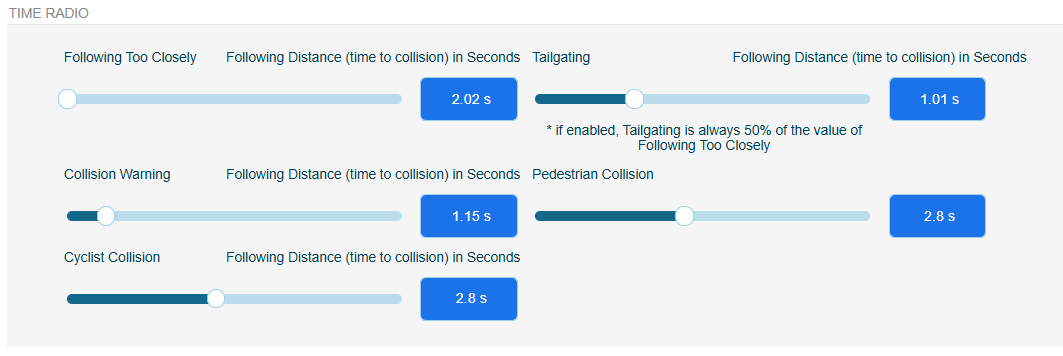

STOP_SIGN_VIOLATION

In [91]:
ssv=vf[vf['Unnamed: 4'].str.contains('STOP_SIGN_VIOLATION')]
#vf_no_seatbelt

vf_date_time=ssv[ssv['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,19])

ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F_ssv.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i])

POTENTIAL_INCIDENT

In [92]:
pi=vf[vf['Unnamed: 4'].str.contains('POTENTIAL_INCIDENT')]
#vf_no_seatbelt

vf_date_time=pi[pi['Unnamed: 9'].str.contains('time')]
vf_date_time['Unnamed: 9']
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]
event=[]

for i in range(0,vf_date_time.shape[0]):
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])
    event.append(vf_date_time.iloc[i,4])

ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F_pi.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ','->',event[i],'->',speed[i])

2026-10-06 07:48:04  ->  1791290884.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:35.08429
2026-10-10 19:36:15  ->  1791678975.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:23.738935
2026-10-13 18:55:58  ->  1791935758.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:19.471928
2026-10-14 01:26:36  ->  1791959196.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:58.79915
2026-10-16 05:50:51  ->  1792147851.0  ->  -> event:"POTENTIAL_INCIDENT_MEDIUM" -> speed:58.137985
2026-10-16 07:07:11  ->  1792152431.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:24.29824
2026-10-20 07:37:09  ->  1792499829.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:80.708305
2026-10-20 08:39:18  ->  1792503558.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:81.230576
2026-10-21 20:45:15  ->  1792633515.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:26.750288
2026-10-24 17:00:45  ->  1792879245.0  ->  -> event:"POTENTIAL_INCIDENT_LOW" -> speed:22.987024


HEADWAY_MONITORING_EMERGENCY

In [93]:
vf_headway=vf[vf['Unnamed: 4'].str.contains('HEADWAY')]

vf_date_time=vf_headway[vf_headway['Unnamed: 10'].str.contains('time')]
#vf_date_time['Unnamed: 9']
headway_event=[]
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    headway_event.append(vf_date_time.iloc[i,4])
    aux_date_time.append(float(vf_date_time.iloc[i,10][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])
ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F_hme.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i],headway_event[i])

2026-10-02 08:53:17.800000  ->  1790949197.8  ->  speed:64.34774 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-05 19:56:26.015000  ->  1791248186.015  ->  speed:74.48929 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-14 11:25:53.610000  ->  1791995153.61  ->  speed:79.85824 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-14 19:06:22.394000  ->  1792022782.394  ->  speed:82.64179 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-15 05:49:52.513000  ->  1792061392.513  ->  speed:75.702354 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-15 06:53:50.596000  ->  1792065230.596  ->  speed:71.702034 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-15 08:47:31.791000  ->  1792072051.791  ->  speed:64.85704 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-15 17:26:27.248000  ->  1792103187.248  ->  speed:67.409096 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-22 06:28:56.177000  ->  1792668536.177  ->  speed:85.11051 event:"HEADWAY_MONITORING_EMERGENCY"
2026-10-24 07:56:58.971000  ->  1792846618.971  ->  speed:75.648

FORWARD_COLLISION_WARNING

In [94]:
vf_forward=vf[vf['Unnamed: 4'].str.contains('FORWARD')]

vf_date_time=vf_forward[vf_forward['Unnamed: 10'].str.contains('time')]
#vf_date_time['Unnamed: 9']
vf_forward_event=[]
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    vf_forward_event.append(vf_date_time.iloc[i,4])
    aux_date_time.append(float(vf_date_time.iloc[i,10][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,21])

ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F_fcw.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i],vf_forward_event[i])

2026-10-20 18:47:12  ->  1792540032.0  ->  speed:23.888948 event:"FORWARD_COLLISION_WARNING"


LANE_DEPARTURE

In [95]:
vf_lane_departure=vf[vf['Unnamed: 4'].str.contains('LANE_DEPARTURE')]
vf_lane_departure.head(5)

vf_date_time=vf_lane_departure[vf_lane_departure['Unnamed: 9'].str.contains('time')]
#vf_date_time['Unnamed: 9']
vf_lane_departure=[]
aux_date_time=[]
epoch_date=[]
vf_date_time['Date']='NaN'
speed=[]

for i in range(0,vf_date_time.shape[0]):
    vf_lane_departure.append(vf_date_time.iloc[i,4])
    aux_date_time.append(float(vf_date_time.iloc[i,9][5:18])/1000)
    epoch_date.append(datetime.datetime.fromtimestamp(aux_date_time[i]))
    vf_date_time.iloc[i,103]=str(epoch_date[i])
    speed.append(vf_date_time.iloc[i,20])

ssv_report=pd.DataFrame()
ssv_report['Date']=epoch_date
ssv_report['Speed']=speed

ssv_report.to_csv(r'C:\Users\Jose.Hurtado\Documents\Zonar_projects\data\bus_service\8B51422F_ld.csv')

for i in range(0,len(epoch_date)):
    print(epoch_date[i],' -> ',aux_date_time[i],' -> ',speed[i],'->',vf_lane_departure[i])

2026-10-26 18:52:52  ->  1793058772.0  ->  speed:66.740524 -> event:"LANE_DEPARTURE_WARNING"
2026-10-26 19:01:39  ->  1793059299.0  ->  speed:74.391136 -> event:"LANE_DEPARTURE_WARNING"
2026-10-26 19:08:37  ->  1793059717.0  ->  speed:70.72232 -> event:"LANE_DEPARTURE_WARNING"
2026-10-26 19:29:03  ->  1793060943.0  ->  speed:66.51643 -> event:"LANE_DEPARTURE_WARNING"
2026-10-26 19:44:53  ->  1793061893.0  ->  speed:65.94972 -> event:"LANE_DEPARTURE_WARNING"
2026-10-26 19:50:45  ->  1793062245.0  ->  speed:65.44783 -> event:"LANE_DEPARTURE_WARNING"
2026-10-26 20:58:58  ->  1793066338.0  ->  speed:82.12138 -> event:"LANE_DEPARTURE_WARNING"
2026-10-26 21:04:56  ->  1793066696.0  ->  speed:75.45604 -> event:"LANE_DEPARTURE_WARNING"
2026-10-27 05:31:51  ->  1793097111.0  ->  speed:82.42882 -> event:"LANE_DEPARTURE_WARNING"
2026-10-27 05:58:01  ->  1793098681.0  ->  speed:77.87104 -> event:"LANE_DEPARTURE_WARNING"
2026-10-27 06:06:10  ->  1793099170.0  ->  speed:81.69543 -> event:"LANE_DEPAR